# 01 Preprocess: epochs per subject

Loops over every 64 Hz wristband file. Step 1: cut each night into 30 s epochs and keep only W, N1, N2, N3, R.

Functions live in `src/preprocess.py` and `qc/qc_funcs.py`. Edit them there; `%autoreload` picks up changes.

In [3]:
import os
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT / "src"))
sys.path.insert(0, str(PROJECT / "qc"))

from qc_funcs import load_wristband
from preprocess import find_wristband_files, make_epochs, STAGES_5

DATA_ROOT = Path(os.environ.get("DREAMT_ROOT", PROJECT / "data" / "raw"))
FIG_DIR = PROJECT / "notebooks" / "figs"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 8})

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
files = find_wristband_files(DATA_ROOT)
print(len(files), "subjects:", " ".join(files))

35 subjects: S006 S009 S010 S012 S013 S014 S015 S021 S022 S024 S030 S032 S035 S042 S045 S047 S055 S058 S061 S064 S070 S072 S074 S075 S080 S085 S086 S093 S094 S096 S097 S100 S101 S102 S103


## Loop: label set and epochs per subject

In [5]:
label_counts = {}   # raw per-sample label counts
epochs = {}         # make_epochs output per subject

for subject, path in files.items():
    _, df = load_wristband(path)
    stage = df["Sleep_Stage"].astype(str).to_numpy()
    label_counts[subject] = pd.Series(stage).value_counts()
    epochs[subject] = make_epochs(stage)
    e = epochs[subject]
    print(f"{subject}: {len(e)} epochs, kept {e.keep.sum()}, mixed {(e.raw == 'mixed').sum()}", flush=True)

labels = pd.DataFrame(label_counts).T.fillna(0).astype(int)
print("\nlabel values found across all files:", list(labels.columns))

S006: 1113 epochs, kept 650, mixed 193
S009: 1025 epochs, kept 695, mixed 112
S010: 1129 epochs, kept 664, mixed 160
S012: 1168 epochs, kept 622, mixed 233
S013: 1070 epochs, kept 739, mixed 47
S014: 954 epochs, kept 639, mixed 157
S015: 1236 epochs, kept 772, mixed 183
S021: 1077 epochs, kept 575, mixed 221
S022: 1103 epochs, kept 768, mixed 94
S024: 1129 epochs, kept 819, mixed 0
S030: 1063 epochs, kept 601, mixed 242
S032: 1025 epochs, kept 640, mixed 170
S035: 1070 epochs, kept 599, mixed 112
S042: 1060 epochs, kept 773, mixed 0
S045: 1001 epochs, kept 652, mixed 169
S047: 1044 epochs, kept 557, mixed 173
S055: 1016 epochs, kept 620, mixed 151
S058: 1050 epochs, kept 492, mixed 302
S061: 1100 epochs, kept 634, mixed 216
S064: 1125 epochs, kept 588, mixed 206
S070: 1119 epochs, kept 696, mixed 124
S072: 1043 epochs, kept 540, mixed 193
S074: 1086 epochs, kept 761, mixed 90
S075: 1032 epochs, kept 728, mixed 0
S080: 1066 epochs, kept 636, mixed 90
S085: 1015 epochs, kept 689, mixed 5

In [6]:
rows = {}
for subject, e in epochs.items():
    r = e.raw.value_counts()
    rows[subject] = r
ep_table = pd.DataFrame(rows).T.fillna(0).astype(int)
ep_table["kept"] = [epochs[s].keep.sum() for s in ep_table.index]
ep_table["pct_mixed"] = (100 * ep_table.get("mixed", 0) / ep_table.drop(columns="kept").sum(axis=1)).round(2)
print(ep_table.to_string())

total_kept = int(ep_table.kept.sum())
print(f"\nUSABLE EPOCHS, all subjects: {total_kept} ({total_kept * 30 / 3600:.1f} h)")
print("pooled per stage:")
print(ep_table[STAGES_5].sum().to_string())
print("\nfewest epochs any person has, per stage:")
print(ep_table[STAGES_5].min().to_string())

raw    N1   N2   N3    P    R    W  mixed  kept  pct_mixed
S006   99  210  115  270    0  226    193   650      17.34
S009   30  383    0  218   69  213    112   695      10.93
S010   60  412    0  305   77  115    160   664      14.17
S012   33  360    0  313  117  112    233   622      19.95
S013    7  480   79  284  149   24     47   739       4.39
S014    8  362   63  158   31  175    157   639      16.46
S015   27  476   51  281  177   41    183   772      14.81
S021   45  186    0  281   54  290    221   575      20.52
S022    6  407    0  241   79  276     94   768       8.52
S024   63  373    0  310  100  283      0   819       0.00
S030   12  297   24  220   43  225    242   601      22.77
S032   95  417    0  215   43   85    170   640      16.59
S035   27  422    0  359  106   44    112   599      10.47
S042   51  552   13  287  124   33      0   773       0.00
S045   41  302    0  180   26  283    169   652      16.88
S047   39  343    0  314   81   94    173   557      16.

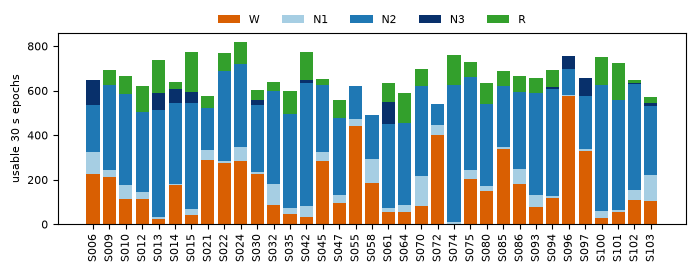

In [7]:
colors = {"W": "#d95f02", "N1": "#a6cee3", "N2": "#1f78b4", "N3": "#08306b", "R": "#33a02c"}
fig, ax = plt.subplots(figsize=(7, 2.8))
bottom = pd.Series(0, index=ep_table.index)
for s in STAGES_5:
    ax.bar(ep_table.index, ep_table[s], bottom=bottom, color=colors[s], label=s, width=0.8)
    bottom += ep_table[s]
ax.set_ylabel("usable 30 s epochs")
ax.tick_params(axis="x", rotation=90)
ax.legend(ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.15))
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_epochs_per_stage.png", dpi=150)
plt.show()

## Step 2: where does the scorer's 30 s grid start?

`find_scoring_offset` per subject. If the grid offset explains the mixed epochs, people with offset 0 should be the ones with 0 mixed.

In [8]:
from preprocess import find_scoring_offset

offsets = {}
for subject, path in files.items():
    stage = pd.read_csv(path, usecols=["Sleep_Stage"])["Sleep_Stage"].astype(str).to_numpy()
    offsets[subject] = find_scoring_offset(stage)

off = pd.DataFrame(offsets).T
off["offset_s"] = off["offset"] / 64
off["pct_mixed_t0_grid"] = ep_table["pct_mixed"]
print(off.to_string())
print(f"\nNON-ZERO OFFSET: {(off.offset != 0).sum()} of {len(off)}")
print("scored-to-scored changes off the anchored grid:", off.n_off_grid_scored.sum(), "of", off.n_changes_scored.sum())
print("changes involving Missing off the anchored grid:", off.n_off_grid_missing.sum(), "of", off.n_changes_missing.sum())

      anchor  offset  n_changes_scored  n_off_grid_scored  n_changes_missing  n_off_grid_missing  offset_s  pct_mixed_t0_grid
S006  519744    1344               192                  0                  0                   0      21.0              17.34
S009  418816     256               111                  0                  0                   0       4.0              10.93
S010  585664      64               160                  0                  0                   0       1.0              14.17
S012  601472     512               233                  0                  0                   0       8.0              19.95
S013  546944    1664                47                  0                  0                   0      26.0               4.39
S014  303552     192               156                  0                  0                   0       3.0              16.46
S015  540032     512               182                  0                  0                   0       8.0            

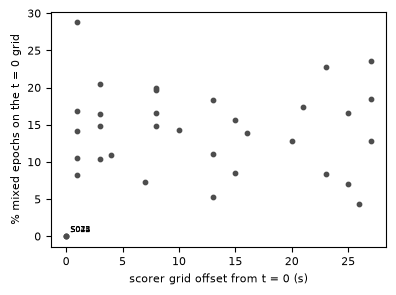

In [9]:
fig, ax = plt.subplots(figsize=(4, 3))
ax.scatter(off.offset_s, off.pct_mixed_t0_grid, s=10, color="0.3")
for s, r in off.iterrows():
    if r.offset == 0:
        ax.annotate(s, (r.offset_s, r.pct_mixed_t0_grid), fontsize=6, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("scorer grid offset from t = 0 (s)")
ax.set_ylabel("% mixed epochs on the t = 0 grid")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_offset_vs_mixed.png", dpi=150)
plt.show()

## Step 3: epochs on each person's own scorer grid

`make_epochs(stage, offset=...)`. Expected: 0 mixed epochs everywhere.

In [10]:
epochs2, stage_cache = {}, {}
for subject, path in files.items():
    stage = pd.read_csv(path, usecols=["Sleep_Stage"])["Sleep_Stage"].astype(str).to_numpy()
    epochs2[subject] = make_epochs(stage, offset=int(off.loc[subject, "offset"]))

ep2 = pd.DataFrame({s: e.raw.value_counts() for s, e in epochs2.items()}).T.fillna(0).astype(int)
ep2["kept"] = [epochs2[s].keep.sum() for s in ep2.index]
ep2["mixed"] = ep2.get("mixed", 0)
print(ep2[STAGES_5 + ["P", "mixed", "kept"]].to_string())
before, after = int(ep_table.kept.sum()), int(ep2.kept.sum())
print(f"\nUSABLE EPOCHS: before {before}  after {after}  (+{after - before}, {after * 30 / 3600:.1f} h)")
print("mixed epochs after:", int(ep2.mixed.sum()))
print("pooled per stage:"); print(ep2[STAGES_5].sum().to_string())
print("people with zero N3:", (ep2.N3 == 0).sum(), " zero REM:", (ep2.R == 0).sum(), " zero W:", (ep2.W == 0).sum())

raw     W   N1   N2   N3    R    P  mixed  kept
S006  252  123  290  178    0  270      0   843
S009  252   67  409    3   76  218      0   807
S010  156  124  458    0   86  305      0   824
S012  172  124  435    0  124  313      0   855
S013   37   19  495   82  153  284      0   786
S014  195   31  431  106   33  158      0   796
S015   71   72  547   75  190  281      0   955
S021  368  121  239    0   68  281      0   796
S022  303   31  445    0   83  241      0   862
S024  283   63  373    0  100  310      0   819
S030  296   50  393   51   53  220      0   843
S032   92  178  496    0   44  215      0   810
S035   64   65  471    2  109  359      0   711
S042   33   51  552   13  124  287      0   773
S045  331  101  352    0   37  180      0   821
S047  115  112  417    0   86  314      0   730
S055  497   95  179    0    0  245      0   771
S058  276  246  272    0    0  256      0   794
S061  123   45  459  118  105  250      0   850
S064   95  118  441    0  140  331      

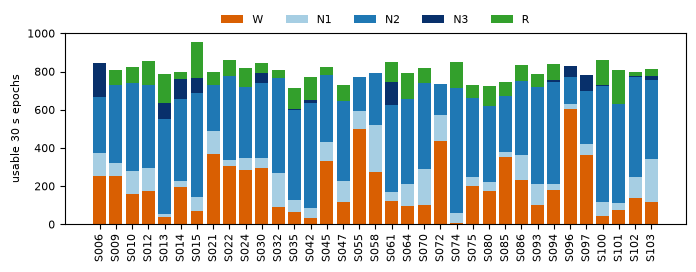

In [11]:
fig, ax = plt.subplots(figsize=(7, 2.8))
bottom = pd.Series(0, index=ep2.index)
for s in STAGES_5:
    ax.bar(ep2.index, ep2[s], bottom=bottom, color=colors[s], label=s, width=0.8)
    bottom += ep2[s]
ax.set_ylabel("usable 30 s epochs")
ax.tick_params(axis="x", rotation=90)
ax.legend(ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.15))
fig.tight_layout(); fig.savefig(FIG_DIR / "fig_epochs_per_stage_anchored.png", dpi=150); plt.show()

## Step 4: band-pass filter, offline vs causal

10 s of S042 in N2 and in W: raw BVP, offline (forward-backward) and causal (forward only) filtered.

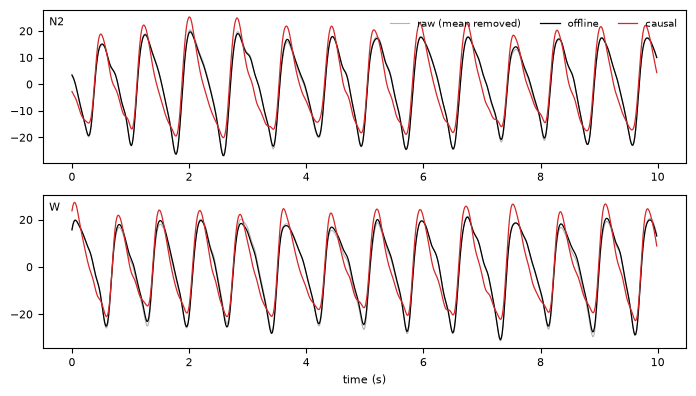

In [12]:
from preprocess import filter_bvp, acc_motion
_, d42 = load_wristband(files["S042"])
bvp = d42["BVP"].to_numpy()
f_off = filter_bvp(bvp)
f_cau = filter_bvp(bvp, causal=True)
e42 = epochs2["S042"]
fig, axes = plt.subplots(2, 1, figsize=(7, 4), sharey=False)
for ax, st in zip(axes, ["N2", "W"]):
    s0 = int(e42[e42.raw == st].start_sample.iloc[len(e42[e42.raw == st]) // 2])
    sl = slice(s0, s0 + 64 * 10)
    t = (np.arange(sl.start, sl.stop) - s0) / 64
    ax.plot(t, bvp[sl] - bvp[sl].mean(), color="0.7", lw=0.8, label="raw (mean removed)")
    ax.plot(t, f_off[sl], color="k", lw=0.9, label="offline")
    ax.plot(t, f_cau[sl], color="tab:red", lw=0.9, label="causal")
    ax.text(0.01, 0.9, st, transform=ax.transAxes)
axes[0].legend(ncol=3, frameon=False, fontsize=7, loc="upper right")
axes[1].set_xlabel("time (s)")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig_filter_offline_causal.png", dpi=150); plt.show()

## Step 5: motion score per epoch, by stage

In [13]:
mot = []
for subject, path in files.items():
    _, d = load_wristband(path)
    e = epochs2[subject]
    m = acc_motion(d.ACC_X, d.ACC_Y, d.ACC_Z, e.start_sample.to_numpy())
    mot.append(pd.DataFrame({"subject": subject, "raw": e.raw, "motion": m}))
mot = pd.concat(mot)
mk = mot[mot.raw.isin(STAGES_5)]
print("median motion score per stage:"); print(mk.groupby("raw").motion.median().reindex(STAGES_5).round(3).to_string())
print("\nmedian motion score in P:", round(mot[mot.raw == "P"].motion.median(), 3))

median motion score per stage:
raw
W     0.323
N1    0.269
N2    0.226
N3    0.143
R     0.213

median motion score in P: 0.511


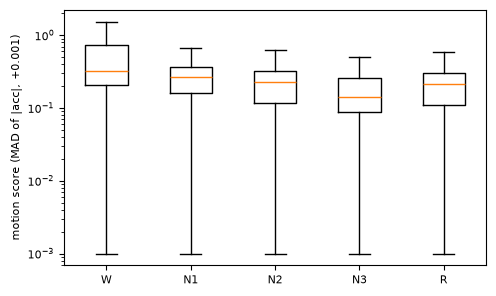

In [14]:
fig, ax = plt.subplots(figsize=(5, 3))
data = [mk[mk.raw == s].motion.to_numpy() + 1e-3 for s in STAGES_5]
ax.boxplot(data, showfliers=False)
ax.set_xticks(range(1, 6), STAGES_5)
ax.set_yscale("log"); ax.set_ylabel("motion score (MAD of |acc|, +0.001)")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig_motion_by_stage.png", dpi=150); plt.show()